# dsQTL benchmark 8 — GM12878 peak specificity

Successor to `dsQTL_benchmark7.ipynb`; model arms and scoring follow **the code** in `IGVF_meeting_figures.ipynb`.

- **Primary:** specificity of the hg38 128-bp bin containing each variant.
- **Sensitivity:** specificity of the merged, adjacent GM12878-positive bins containing it; no gap bridging or nearest-peak assignment.
- **Cache:** genome-wide coverage, binary track × peak matrices, coordinates, breadth, variant labels and model scores. Subsequent analysis uses ordinary NumPy/TSV files.
- **Tracks ≠ unique cell types:** all 674 experiments count toward breadth, including replicates; this matches the quoted track-based method.
- Run cells in order. The initial coverage build is already launched separately; the default below requires its completed cache.

## Method choices

- Sum each nonoverlapping **128-bp bin** from chromosome coordinate 0. Include chr1–22, X and Y; discard incomplete terminal bins.
- Use the supplied coverage **as stored**, in its common normalized units. The preprocessing code also applies scale 2, soft/hard clipping and blacklist/unmappability adjustments. Do not apply scale 2 again or attempt to reverse clipping.
- Per track, λ = mean summed coverage across all tested genome-wide bins. The 100-million-read normalization target is **not** λ per bin; processed track totals can differ.
- Approximate integer count `k = floor(bin_sum)`; upper-tail p = `Poisson.sf(k−1, λ)`. Flooring is explicit and avoids treating a fractional value as a literal raw-read count.
- Apply **Benjamini–Hochberg at 0.01 separately per track across the whole genome**, including zero bins. A count histogram gives the same BH rejection set as sorting all discrete p-values, without billions of p-values in memory.
- **Exploratory processed-coverage test:** nominal BH 0.01 is not calibrated raw-count FDR. This is a global-Poisson approximation, not a MACS2 run or a local-background test.
- GM12878-positive = present in ≥30% of its two tracks (indices 12, 69), therefore at least one track.
- Bin breadth = number of the 674 tracks calling the bin. Split genome-wide GM12878 bins at their median: **≤ median = high specificity; > median = low specificity**. Keep ties together, so halves need not have equal sizes. “High” is relative breadth, not proof of GM12878 exclusivity.
- Merged-peak presence = ≥50% of its constituent bins called in a track. Save the **fraction** too. Split merged peaks at their own genome-wide median breadth. This extension is a sensitivity analysis; longer peaks may have different behavior.

References: [SciPy Poisson](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.poisson.html), [SciPy BH implementation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html). The reference paper was not identified; the recipe above follows the supplied description.

## Cache builder (one-time scan)

- Read each compressed source chunk once; carry bin fragments across 1-Mb chunk boundaries.
- Validate finite, nonnegative source values and expected array layout; omitted chunks use the declared zero fill, with their indices inventoried in the manifest.
- The supplied store omits 180 of 3,102 chunks; standard Zarr semantics treat these as zero-filled. This includes them in the genome-wide null and test count. The manifest records the omitted chunks; it cannot distinguish intentional sparse storage from incomplete source generation.
- Two workers by default (four in the batch job); completed chromosomes resume from `coverage.done.json`. An interrupted chromosome restarts.
- Estimated persistent coverage size: ~65 GB float32, plus call matrices and tables. Keep coverage to support new thresholds without rereading the source.
- Headless export: `dsQTL_benchmark8_pipeline.py`; progress: `dsQTL_benchmark8_cache/build.log`.

In [1]:
"""Headless export of dsQTL_benchmark8 notebook cache cells; no model inference."""
from pathlib import Path
import json, hashlib, os, time
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
from scipy.stats import poisson
import numcodecs
import torch
import fcntl

ROOT = Path('/data1/lesliec/sarthak/caduceus/notebooks/benchmarks/dsqtl')
CACHE = ROOT / 'dsQTL_benchmark8_cache'
SOURCE = Path('/data1/lesliec/sarthak/data/DK_zarr/zarr_arrays/dnase_chunkchrom_reprocessed.zarr')
TARGETS = Path('/data1/lesliec/sarthak/data/DK_zarr/targets_DNase_borzoi.txt')
DSQ = Path('/data1/lesliec/sarthak/data/joint_playground/dsQTL')
BIMS = Path('/data1/deyk/extras/1000G_BIMS_hg38')
BIN = 128
FDR = 0.01
GM_FRACTION = 0.30
MERGED_FRACTION = 0.50  # >= half the constituent bins called in a track
CHROMS = [f'chr{i}' for i in range(1,23)] + ['chrX','chrY']
WORKERS = int(os.environ.get('DSQTL8_WORKERS', '2'))

def progress(*parts):
    message = ' '.join(map(str, parts))
    print(message, flush=True)
    with (CACHE / 'build.log').open('a') as log:
        log.write(time.strftime('%Y-%m-%d %H:%M:%S ') + message + '\n')

def atomic_json(path, value):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(value, indent=2, allow_nan=False))
    tmp.replace(path)

def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def metadata(path):
    m = json.loads((Path(path)/'.zarray').read_text())
    assert m['zarr_format'] == 2 and m['order'] == 'C' and not m.get('filters')
    assert m.get('dimension_separator', '.') == '.'
    return m

def read_chunk(path, m, indices):
    """Read a local Zarr-v2 chunk once, without asynchronous Zarr I/O.

    Valid only for the checked C-order, no-filter, dot-separated stores here.
    Absent chunks use the declared Zarr fill value; the manifest inventories them.
    """
    p = Path(path) / '.'.join(map(str, indices))
    if not p.exists():
        # Omitted chunks are legal in sparse Zarr stores (often assembly gaps).
        assert 'fill_value' in m and m['fill_value'] == 0, 'Unexpected sparse fill value'
        return np.zeros(m['chunks'], dtype=m['dtype'])
    raw = p.read_bytes()
    if m['compressor'] is not None:
        raw = numcodecs.get_codec(m['compressor']).decode(raw)
    return np.frombuffer(raw, dtype=m['dtype']).reshape(m['chunks'])

def init_cache():
    CACHE.mkdir(exist_ok=True)
    tracks = pd.read_csv(TARGETS, sep='\t')
    assert np.array_equal(tracks['index'], np.arange(len(tracks)))
    gm = np.flatnonzero(tracks.description.eq('DNASE:GM12878'))
    assert len(gm) > 0
    metas = {ch: metadata(SOURCE/ch) for ch in CHROMS}
    for m in metas.values():
        assert m['shape'][0] == len(tracks) and m['chunks'][0] == len(tracks)
        assert m['dtype'] == '<f2'
    omitted = {ch: [j for j in range((m['shape'][1]+m['chunks'][1]-1)//m['chunks'][1])
                    if not (SOURCE/ch/f'0.{j}').exists()] for ch,m in metas.items()}
    config = dict(version=2, source=str(SOURCE), targets_sha256=digest(TARGETS),
                  bin_bp=BIN, chromosomes=CHROMS, metadata=metas,
                  pooling='sum float32; floor only for approximate Poisson',
                  partial_terminal_bins='excluded', invalid_values='fail',
                  missing_source_chunks='declared zero fill; see omitted_chunks', omitted_chunks=omitted, signal='processed normalized coverage; no inverse clipping')
    p = CACHE/'coverage_manifest.json'
    if p.exists():
        assert json.loads(p.read_text()) == config, 'Cache config mismatch: use a new CACHE directory.'
    else:
        atomic_json(p, config)
    tracks.to_csv(CACHE/'tracks.tsv',sep='\t',index=False)
    return tracks, gm, metas

def pool_chrom(ch, m):
    """One pass per source chunk; carry partial bins across 1-Mb chunk edges."""
    out = CACHE/ch
    out.mkdir(exist_ok=True)
    marker = out/'coverage.done.json'
    if marker.exists():
        return json.loads(marker.read_text())
    t = time.time()
    nt, length = m['shape']; chunk_bp = m['chunks'][1]
    nb = length//BIN
    temp = out/'coverage.tmp.npy'
    pooled = np.lib.format.open_memmap(temp,mode='w+',dtype='float32',shape=(nt,nb))
    # Source is hard-clipped to <=128 per base; retain explicit bounds checks.
    hist = np.zeros((nt, BIN*128+1),dtype=np.int64)
    sums = np.zeros(nt, dtype=np.float64)
    carry = np.empty((nt,0),dtype=np.float32)
    written = 0
    for j,start in enumerate(range(0,length,chunk_bp)):
        x = read_chunk(SOURCE/ch,m,(0,j))[:, :min(chunk_bp,length-start)]
        # Exact CPU float16 -> float32 conversion; torch avoids NumPy's slow half conversion.
        # Copy gives torch a writable buffer; neither the decoded input nor source is modified.
        x = torch.from_numpy(x.copy()).float().numpy()
        # min/max propagate NaN and reject +/-Inf as well as out-of-range values.
        assert x.min() >= 0 and x.max() <= 128, (ch,j,'invalid coverage')
        if carry.shape[1]:
            x = np.concatenate((carry,x),axis=1)
        n = x.shape[1]//BIN
        y = x[:,:n*BIN].reshape(nt,n,BIN).sum(axis=2,dtype=np.float32)
        carry = x[:,n*BIN:].copy()
        pooled[:,written:written+n] = y
        sums += y.sum(axis=1,dtype=np.float64)
        for tr in range(nt):
            hist[tr] += np.bincount(np.floor(y[tr]).astype(np.int64),minlength=hist.shape[1])
        written += n
        if j % 10 == 0:
            progress(f'{ch}: {start/1e6:.0f}/{length/1e6:.0f} Mb, {time.time()-t:.0f}s')
    assert written == nb and np.all(hist.sum(axis=1)==nb)
    pooled.flush(); del pooled
    temp.replace(out/'coverage.npy')
    np.savez(out/'histogram.npz', histogram=hist, sums=sums)
    result = dict(chrom=ch,bins=nb,excluded_terminal_bp=length % BIN,seconds=time.time()-t)
    atomic_json(marker,result)
    progress('Pooled', result)
    return result

def bh_count_threshold(hist, lam, alpha):
    """Exact BH rejection set for discrete Poisson p-values using tied counts.

    At count k, rank is the number of bins with count >= k. The smallest k
    passing p(k)<=alpha*rank/m is the BH count cutoff, including all ties.
    """
    n = hist.sum()
    k = np.flatnonzero(hist)
    tail = np.cumsum(hist[::-1],dtype=np.int64)[::-1]
    p = poisson.sf(k-1,lam)
    ok = p <= alpha*tail[k]/n
    return int(k[ok][0]) if ok.any() else int(len(hist))

def call_peaks(tracks, gm):
    settings = dict(fdr=FDR, gm_fraction=GM_FRACTION, merged_fraction=MERGED_FRACTION,
                    gm_indices=gm.tolist(), median_ties='breadth <= median: high specificity',
                    merged_presence='fraction of constituent bins >= merged_fraction')
    marker = CACHE/'peaks.done.json'
    if marker.exists():
        assert json.loads(marker.read_text()) == settings, 'Peak settings changed: use a new cache or remove peak products first.'
        return
    nt = len(tracks)
    hist = np.zeros((nt,BIN*128+1),dtype=np.int64)
    sums = np.zeros(nt,dtype=np.float64)
    for ch in CHROMS:
        with np.load(CACHE/ch/'histogram.npz') as h:
            hist += h['histogram']; sums += h['sums']
    nb = int(hist[0].sum()); assert np.all(hist.sum(axis=1)==nb)
    lam = sums/nb  # empirical global mean per track, NOT 100M / genome by assumption
    thresholds = np.array([bh_count_threshold(hist[i],lam[i],FDR) for i in range(nt)])
    report = tracks.copy()
    report['lambda_bin'] = lam; report['count_threshold'] = thresholds
    report['n_tested_bins'] = nb
    report['n_peak_bins'] = [hist[i,thresholds[i]:].sum() for i in range(nt)]
    report['p_at_threshold'] = poisson.sf(thresholds-1,lam)
    report.to_csv(CACHE/'track_thresholds.tsv',sep='\t',index=False)
    gm_needed = int(np.ceil(GM_FRACTION*len(gm)))
    bin_tables, merged_tables = [], []
    for ch in CHROMS:
        folder = CACHE/ch
        y = np.load(folder/'coverage.npy',mmap_mode='r')
        n = y.shape[1]
        # Keep all-genome bit calls, and a union-of-peaks matrix in track x peak orientation.
        packed = np.lib.format.open_memmap(folder/'calls.packed.npy',mode='w+',dtype='uint8',shape=(nt,(n+7)//8))
        breadth = np.zeros(n,dtype=np.uint16)
        gm_count = np.zeros(n,dtype=np.uint8)
        for tr in range(nt):
            calls = y[tr] >= thresholds[tr]  # equivalent to floor(y) >= integer threshold
            packed[tr] = np.packbits(calls,bitorder='little')
            breadth += calls
            if tr in gm: gm_count += calls
        packed.flush()
        union = np.flatnonzero(breadth>0)
        np.save(folder/'peak_bin_indices.npy',union.astype(np.int32))
        union_mat = np.lib.format.open_memmap(folder/'tracks_x_peak_bins.npy',mode='w+',dtype='uint8',shape=(nt,len(union)))
        gm_bins = np.flatnonzero(gm_count >= gm_needed)
        bt = pd.DataFrame(dict(chrom=ch,start=gm_bins*BIN,end=(gm_bins+1)*BIN,
                               bin_index=gm_bins,breadth=breadth[gm_bins],gm_tracks=gm_count[gm_bins]))
        bin_tables.append(bt)
        if len(gm_bins):
            starts = np.r_[0,np.flatnonzero(np.diff(gm_bins)>1)+1]
            ends = np.r_[starts[1:],len(gm_bins)]
            lo,hi = gm_bins[starts],gm_bins[ends-1]+1
        else:
            lo=hi=np.array([],dtype=int)
        fraction = np.lib.format.open_memmap(folder/'tracks_x_merged_fraction.npy',mode='w+',dtype='float32',shape=(nt,len(lo)))
        merged = np.lib.format.open_memmap(folder/'tracks_x_merged_presence.npy',mode='w+',dtype='uint8',shape=(nt,len(lo)))
        for tr in range(nt):
            calls = np.unpackbits(packed[tr],bitorder='little',count=n)
            union_mat[tr] = calls[union]
            cs = np.r_[0,np.cumsum(calls,dtype=np.int64)]
            fraction[tr] = (cs[hi]-cs[lo])/(hi-lo)
            merged[tr] = fraction[tr] >= MERGED_FRACTION
        union_mat.flush(); fraction.flush(); merged.flush()
        mt = pd.DataFrame(dict(chrom=ch,start=lo*BIN,end=hi*BIN,merged_index=np.arange(len(lo)),
                               n_bins=hi-lo,breadth=merged.sum(axis=0,dtype=np.uint16)))
        merged_tables.append(mt)
        np.save(folder/'breadth.npy',breadth)
        np.save(folder/'gm_track_count.npy',gm_count)
        progress(ch,'union bins',len(union),'GM bins',len(gm_bins),'merged',len(lo))
        del packed,union_mat,fraction,merged,y
    for kind,tables in [('bins',bin_tables),('merged',merged_tables)]:
        table = pd.concat(tables,ignore_index=True)
        assert len(table)>0, f'No GM peaks ({kind})'
        median = float(table.breadth.median())
        table['specificity'] = np.where(table.breadth<=median,'high_specificity','low_specificity')
        table['median_breadth'] = median
        table['peak_id'] = table.chrom+':'+table.start.astype(str)+'-'+table.end.astype(str)
        table.to_csv(CACHE/f'gm12878_{kind}.tsv.gz',sep='\t',index=False)
    atomic_json(marker,settings)

def build_cache():
    CACHE.mkdir(exist_ok=True)
    # Prevent two notebook/headless processes from writing the same cache concurrently.
    with (CACHE/'build.lock').open('w') as lock:
        fcntl.flock(lock, fcntl.LOCK_EX)
        numcodecs.blosc.set_nthreads(1)
        torch.set_num_threads(1)
        tracks,gm,metas = init_cache()
        progress('Build started; workers:', WORKERS)
        with ThreadPoolExecutor(max_workers=WORKERS) as pool:
            list(pool.map(lambda ch: pool_chrom(ch,metas[ch]),CHROMS))
        call_peaks(tracks,gm)
        progress('Genome-wide peak cache complete')



In [2]:
# False for ordinary reruns. Set True only to build/resume a missing cache,
# a file lock prevents concurrent cache writers.
BUILD_IF_MISSING = os.environ.get('DSQTL8_BUILD', '0') == '1'
if not (CACHE / 'peaks.done.json').exists():
    if BUILD_IF_MISSING:
        build_cache()
    else:
        raise RuntimeError(f'Genome-wide build not complete. See {CACHE / "build.log"}. '
                           'The launched job will populate this notebook automatically when finished.')
tracks = pd.read_csv(CACHE / 'tracks.tsv', sep='\t')
thresholds = pd.read_csv(CACHE / 'track_thresholds.tsv', sep='\t')
gm_bins = pd.read_csv(CACHE / 'gm12878_bins.tsv.gz', sep='\t')
gm_merged = pd.read_csv(CACHE / 'gm12878_merged.tsv.gz', sep='\t')
display(thresholds.loc[tracks.description.eq('DNASE:GM12878'),
                       ['index','identifier','description','lambda_bin','count_threshold','n_peak_bins']])
for kind, peaks in [('bins', gm_bins), ('merged', gm_merged)]:
    print(kind, 'median breadth:', peaks.median_breadth.iloc[0],
          'counts:', peaks.specificity.value_counts().to_dict())

Build started; workers: 4


chr1: 0/249 Mb, 5s


chr3: 0/198 Mb, 5s


chr4: 0/190 Mb, 5s


chr2: 0/242 Mb, 6s


...

chrX union bins 907921 GM bins 86348 merged 45016


chrY union bins 48794 GM bins 66 merged 56


Genome-wide peak cache complete


,index,identifier,description,lambda_bin,count_threshold,n_peak_bins
12,12,ENCFF093VXI,DNASE:GM12878,12.056360,25,2120044
69,69,ENCFF915DFR,DNASE:GM12878,10.379547,23,1859061


bins median breadth: 108.0 counts: {'high_specificity': 1625232, 'low_specificity': 1621518}
merged median breadth: 68.0 counts: {'high_specificity': 678062, 'low_specificity': 669513}


## Matrix access — no source Zarr

All coordinates are **hg38, 0-based, half-open**. Matrix rows follow `tracks.tsv` exactly.

| Per-chromosome file | Columns / values |
|---|---|
| `coverage.npy` | All chromosome bins; float32 summed coverage; column j = `[128j, 128(j+1))` |
| `calls.packed.npy` | All-bin binary calls, packed along bins; little-endian bit order |
| `peak_bin_indices.npy` | Genomic bin indices of the union of peaks in any track |
| `tracks_x_peak_bins.npy` | Track × union peak-bin; uint8 0/1; columns match `peak_bin_indices.npy` |
| `tracks_x_merged_fraction.npy` | Track × merged GM12878 peak; fraction of constituent bins called |
| `tracks_x_merged_presence.npy` | Same columns, uint8 0/1 at ≥50% coverage |
| `breadth.npy`, `gm_track_count.npy` | Breadth and GM12878 support for every chromosome bin |

`gm12878_bins.tsv.gz` and `gm12878_merged.tsv.gz` give genome-wide GM12878 coordinates, breadth and group labels. For merged matrices, select the chromosome and use `merged_index` as the column index.

In [3]:
# Example: recover a labeled slice of the binary matrix in milliseconds.
MATRIX_CHROM = 'chr1'
peak_indices = np.load(CACHE / MATRIX_CHROM / 'peak_bin_indices.npy', mmap_mode='r')
peak_calls = np.load(CACHE / MATRIX_CHROM / 'tracks_x_peak_bins.npy', mmap_mode='r')
print('Track × peak-bin matrix:', peak_calls.shape)
example_columns = np.arange(min(8, len(peak_indices)))
display(pd.DataFrame(peak_calls[:, example_columns],
    index=tracks['identifier'],
    columns=[f'{MATRIX_CHROM}:{int(j)*BIN}-{(int(j)+1)*BIN}' for j in peak_indices[example_columns]]).iloc[:15])

Track × peak-bin matrix: (674, 1596155)


,chr1:10112-10240,chr1:10240-10368,chr1:13312-13440,chr1:13952-14080,chr1:16128-16256,chr1:16256-16384,chr1:17408-17536,chr1:29312-29440
identifier,,,,,,,,
ENCFF833POA,0,0,0,0,0,0,0,0
ENCFF110QGM,0,0,0,0,0,0,0,0
ENCFF880MKD,0,0,0,0,1,1,1,0
ENCFF463ZLQ,0,0,0,0,0,0,0,0
ENCFF890OGQ,0,0,0,0,0,0,0,0
ENCFF996AEF,0,0,0,0,0,0,0,0
ENCFF660YSU,0,0,0,0,0,0,0,0
ENCFF787MSC,0,0,0,0,0,0,0,0
ENCFF568LMQ,0,0,0,0,0,0,0,0


## Variant mapping and model scores

- Use the same hg38 BIM rsID lookup as `evals/dsqtl_onemodel.py`; subtract 1 from BIM positions. Never overlap hg19 positions with the hg38 coverage.
- Require matching unordered allele pairs and unique rsIDs. Save failures explicitly; exclude them from peak stratification. This checks BIM agreement, not a fresh reference-genome allele validation.
- Preserve all 17,506 benchmark rows and prediction order. Positive label = 1; negative label = −1.
- Copy the poster's 12 model arms. Enformer: bins 440:456; Borzoi: 3040:3104 (both 2,048 bp). cis-Mamba and AlphaGenome: their full stored profiles (500 and 1,000 positions respectively); retain the poster's scoring rather than claim all arms use the same physical window.
- ChromBPNet: published DNase/ATAC logFC and IPS, joined by hg19 coordinate with allele/label checks; distinct scoring windows as in the poster.
- Rank by absolute log2 mean(ref)/mean(alt), or absolute released ChromBPNet score. Common support requires every arm to have a finite score and positive ref/alt means. **Zero effect is valid**; neither zero effect nor a model's predictions define specificity.
- Default reruns read cached coordinates and scores directly. Source files are read only when those caches are absent.

In [4]:
"""Headless export of dsQTL_benchmark8 notebook mapping and scoring cells."""
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from scipy.stats import spearmanr
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

CBP = Path('/data1/lesliec/sarthak/data/chrombpnet/dsqtls.yoruba.lcls.benchmarking.all.tsv')
ARMS = [
 ('cis-Mamba (GM12878 DNase logFC)','ours','nomlm_maskonly.npy'),
 ('Enformer (pretrained)','enformer','enformer_dsqtl.npy'),
 ('Enformer retrained (GM12878)','enformer','enformer_dsqtl_retrained-dsqtl.npy'),
 ('Borzoi (pretrained)','borzoi','borzoi_dsqtl_pretrained_1288.npy'),
 ('Borzoi LoRA (GM12878)','borzoi','borzoi_dsqtl_lorav2.npy'),
 ('Borzoi full FT (GM12878)','borzoi','borzoi_dsqtl_trunk.npy'),
 ('Borzoi from scratch (GM12878)','borzoi','borzoi_dsqtl_scratch.npy'),
 ('AlphaGenome','alphagenome','alphagenome_dsqtl.zarr'),
 ('ChromBPNet (GM12878 DNase logFC)','chrombpnet',('encsr000emt','logfc')),
 ('ChromBPNet (GM12878 DNase IPS)','chrombpnet',('encsr000emt','ips')),
 ('ChromBPNet (GM12878 ATAC logFC)','chrombpnet',('encsr637xsc','logfc')),
 ('ChromBPNet (GM12878 ATAC IPS)','chrombpnet',('encsr637xsc','ips')),
]

def map_variants():
    q = pd.read_csv(DSQ/'filtered_dsqtls.txt',sep='\t')
    q.insert(0,'variant_row',np.arange(len(q)))
    q['label_binary'] = (q.label==1).astype(int)
    assert set(q.label.unique()) <= {-1,0,1} and not q.SNPname2.duplicated().any()
    destination = CACHE/'variants_hg38.tsv.gz'
    fingerprint = dict(variants_sha256=digest(DSQ/'filtered_dsqtls.txt'),mapping='prediction scripts rsID -> hg38 BIM, bp minus 1',
                       bims=[dict(path=str(BIMS/f'1000G.EUR.QC.{c}.bim'),size=(BIMS/f'1000G.EUR.QC.{c}.bim').stat().st_size,
                                  mtime_ns=(BIMS/f'1000G.EUR.QC.{c}.bim').stat().st_mtime_ns) for c in range(1,23)])
    if destination.exists():
        assert json.loads((CACHE/'mapping_manifest.json').read_text())==fingerprint
        return pd.read_csv(destination,sep='\t')
    q['pos0_hg38'] = -1
    q['mapping_status'] = 'missing_rsid'
    q['chrom_hg38'] = q.chrom_hg19
    for ch,rows in q.groupby('chrom_hg19'):
        wanted = set(rows.SNPname2)
        hits=[]
        for block in pd.read_csv(BIMS/f'1000G.EUR.QC.{ch[3:]}.bim',sep='\t',header=None,
                                 names=['chrom','rsid','cm','pos','a1','a2'],
                                 usecols=['rsid','pos','a1','a2'],chunksize=500000):
            hits.append(block[block.rsid.isin(wanted)])
        hit = pd.concat(hits).set_index('rsid')
        assert not hit.index.duplicated().any(), f'Ambiguous BIM rsID in {ch}'
        aligned = hit.reindex(rows.SNPname2)
        found = aligned.pos.notna().to_numpy()
        alleles = ((aligned.a1.to_numpy()==rows.allele1.to_numpy()) & (aligned.a2.to_numpy()==rows.allele2.to_numpy())) | \
                  ((aligned.a2.to_numpy()==rows.allele1.to_numpy()) & (aligned.a1.to_numpy()==rows.allele2.to_numpy()))
        valid = found & alleles
        q.loc[rows.index[found & ~alleles],'mapping_status'] = 'allele_mismatch'
        q.loc[rows.index[valid],'mapping_status'] = 'mapped'
        q.loc[rows.index[valid],'pos0_hg38'] = aligned.pos.to_numpy()[valid].astype(np.int64)-1
    q.to_csv(destination,sep='\t',index=False)
    atomic_json(CACHE/'mapping_manifest.json',fingerprint)
    print('Mapping:',q.mapping_status.value_counts().to_dict(),flush=True)
    return q

def score_variants(q):
    path = CACHE/'model_scores.npz'
    paths = [DSQ/f for _,_,f in ARMS if isinstance(f,str)] + [CBP]
    provenance = dict(version=1,variants_sha256=digest(DSQ/'filtered_dsqtls.txt'),arms=ARMS,
                      files=[dict(path=str(p),size=p.stat().st_size,mtime_ns=p.stat().st_mtime_ns) for p in paths])
    # JSON canonicalization converts tuples consistently on fresh and cached runs.
    provenance = json.loads(json.dumps(provenance))
    if path.exists():
        assert json.loads((CACHE/'scores_manifest.json').read_text())==provenance
        with np.load(path) as d: return d['scores'], d['scorable']
    scores = np.full((len(q),len(ARMS)),np.nan)
    scorable = np.zeros_like(scores,dtype=bool)
    t = pd.read_csv(CBP,sep='\t')
    t['_key'] = t['var.chr'].astype(str)+':'+t['var.pos_hg19'].astype(str)
    # Require duplicate keys to agree for every field used before retaining one.
    needed=['var.allele1','var.allele2','obs.label'] + [f'pred.chrombpnet.{f[0]}.varscore.{f[1]}' for _,_,f in ARMS if isinstance(f,tuple)]
    du=t[t._key.duplicated(keep=False)]
    if len(du): assert du.groupby('_key')[needed].nunique(dropna=False).le(1).all().all()
    r=t.drop_duplicates('_key').set_index('_key').reindex(q.chrom_hg19+':'+q.pos_hg19.astype(str))
    for i,(name,family,f) in enumerate(ARMS):
        if isinstance(f,tuple):
            s=r[f'pred.chrombpnet.{f[0]}.varscore.{f[1]}'].to_numpy(dtype=float)
            ok=np.isfinite(s)
            for cb,qc in [('var.allele1','allele1'),('var.allele2','allele2'),('obs.label','label')]:
                assert np.array_equal(r[cb].to_numpy()[ok],q[qc].to_numpy()[ok])
            scores[:,i]=np.abs(s); scorable[:,i]=ok
        else:
            if f.endswith('.zarr'):
                # AlphaGenome is one variant per chunk; matches the poster's full stored profile.
                m=metadata(DSQ/f)
                assert m['shape'][0]==len(q) and m['chunks']==[1,m['shape'][1],2]
                a=np.empty(m['shape'],dtype=m['dtype'])
                for j in range(len(q)): a[j]=read_chunk(DSQ/f,m,(j,0,0))[0]
            else:
                a=np.load(DSQ/f,mmap_mode='r')
            assert a.ndim==3 and a.shape[0]==len(q) and a.shape[2]==2
            if 'borzoi' in f:
                assert a.shape[1]==6144
                a=a[:,3040:3104,:]
            elif 'enformer' in f:
                assert a.shape[1]==896
                a=a[:,440:456,:]
            a=np.asarray(a,dtype=np.float64)
            assert np.isfinite(a).all() and (a>=0).all(), name
            means=a.mean(axis=1)
            ok=(means[:,0]>0)&(means[:,1]>0)
            s=np.zeros(len(q))
            s[ok]=np.abs(np.log2(means[ok,0]/means[ok,1]))
            scores[:,i]=s; scorable[:,i]=ok & np.isfinite(s)
        print(name, 'scorable',int(scorable[:,i].sum()),flush=True)
    np.savez_compressed(path,scores=scores,scorable=scorable)
    atomic_json(CACHE/'scores_manifest.json',provenance)
    return scores,scorable

def annotate_variants(q):
    """Half-open hg38 intervals; variants outside GM peaks stay explicitly unassigned."""
    out=q.copy()
    out['bin_index']=out.pos0_hg38//BIN
    for kind in ['bins','merged']:
        peaks=pd.read_csv(CACHE/f'gm12878_{kind}.tsv.gz',sep='\t')
        out[f'{kind}_specificity']='outside_GM12878_peaks'
        out[f'{kind}_breadth']=np.nan
        out[f'{kind}_peak_id']=''
        out.loc[out.mapping_status!='mapped',f'{kind}_specificity']='unmapped'
        for ch,rows in out[out.mapping_status=='mapped'].groupby('chrom_hg38'):
            p=peaks[peaks.chrom==ch].sort_values('start')
            if p.empty: continue
            pos=rows.pos0_hg38.to_numpy()
            j=np.searchsorted(p.start.to_numpy(),pos,side='right')-1
            ok=(j>=0)&(pos<p.end.to_numpy()[np.maximum(j,0)])
            rr=rows.index[ok]; pp=p.iloc[j[ok]]
            for suffix in ['specificity','breadth','peak_id']:
                out.loc[rr,f'{kind}_{suffix}']=pp[suffix].to_numpy()
    out.to_csv(CACHE/'variant_specificity.tsv.gz',sep='\t',index=False)
    return out

def metric_values(y,s):
    if len(y)==0 or np.unique(y).size<2: return np.nan,np.nan
    return average_precision_score(y,s),roc_auc_score(y,s)

def stratified_metrics(v,scores,scorable,n_boot=200,seed=42):
    """Cluster bootstrap resamples merged peaks; same draws for all model arms."""
    common=scorable.all(axis=1)
    y=v.label_binary.to_numpy()
    rows=[]; differences=[]
    rng=np.random.default_rng(seed)
    for kind in ['bins','merged']:
        for group in ['all_common','all_GM12878_peaks','high_specificity','low_specificity','outside_GM12878_peaks']:
            if group=='all_common': mask=common.copy()
            elif group=='all_GM12878_peaks': mask=common & v[f'{kind}_specificity'].isin(['high_specificity','low_specificity']).to_numpy()
            else: mask=common & v[f'{kind}_specificity'].eq(group).to_numpy()
            idx=np.flatnonzero(mask)
            # All variants sharing a merged peak remain together, including in bin analysis.
            cl=v.iloc[idx].merged_peak_id.fillna('').to_numpy().astype(str)
            fallback=(v.iloc[idx].chrom_hg38+':'+v.iloc[idx].bin_index.astype(str)).to_numpy()
            cl=np.where(cl=='',fallback,cl)
            unique,inv=np.unique(cl,return_inverse=True)
            samples=[np.flatnonzero(inv==j) for j in range(len(unique))]
            boot=np.full((n_boot,len(ARMS)),np.nan)
            if len(unique)>1 and np.unique(y[idx]).size==2:
                for b in range(n_boot):
                    take=np.concatenate([samples[j] for j in rng.integers(0,len(samples),len(samples))])
                    yy=y[idx[take]]
                    if np.unique(yy).size<2: continue
                    for a in range(len(ARMS)):
                        boot[b,a]=average_precision_score(yy,scores[idx[take],a])
            for a,(name,family,_) in enumerate(ARMS):
                ap,roc=metric_values(y[idx],scores[idx,a])
                good=np.isfinite(boot[:,a])
                ci=np.percentile(boot[good,a],[2.5,97.5]) if good.any() else [np.nan,np.nan]
                prevalence=float(y[idx].mean()) if len(idx) else np.nan
                rows.append(dict(definition=kind,stratum=group,model=name,family=family,n=len(idx),
                                 positives=int(y[idx].sum()),negative=int(len(idx)-y[idx].sum()),n_clusters=len(unique),
                                 prevalence=prevalence,AP=ap,AUROC=roc,AP_minus_prevalence=ap-prevalence,
                                 AP_ci_low=ci[0],AP_ci_high=ci[1],valid_bootstraps=int(good.sum())))
                good=good & np.isfinite(boot[:,0])
                delta=boot[good,0]-boot[good,a]
                ci=np.percentile(delta,[2.5,97.5]) if len(delta) else [np.nan,np.nan]
                base=metric_values(y[idx],scores[idx,0])[0]
                differences.append(dict(definition=kind,stratum=group,reference=ARMS[0][0],model=name,
                                        delta_AP=base-ap,ci_low=ci[0],ci_high=ci[1],valid_bootstraps=len(delta)))
    table=pd.DataFrame(rows); table.to_csv(CACHE/'stratified_metrics.tsv',sep='\t',index=False)
    pd.DataFrame(differences).to_csv(CACHE/'paired_model_differences.tsv',sep='\t',index=False)
    return table

def variant_comparisons(v,scores,scorable):
    common=scorable.all(axis=1)
    rows=[]
    for kind in ['bins','merged']:
        eligible=common & v[f'{kind}_specificity'].isin(['high_specificity','low_specificity']).to_numpy()
        if not eligible.any(): continue
        # Fixed global threshold within GM peaks, shared across the two strata for each model.
        cut=np.quantile(scores[eligible],.9,axis=0)
        top=(scores>=cut) & eligible[:,None]
        for group in ['high_specificity','low_specificity']:
            mask=eligible & v[f'{kind}_specificity'].eq(group).to_numpy()
            pos=mask & v.label_binary.eq(1).to_numpy()
            for a,(name,_,_) in enumerate(ARMS):
                selected=top[:,a]&mask
                rows.append(dict(definition=kind,stratum=group,model=name,threshold=cut[a],
                                 n=int(mask.sum()),n_selected=int(selected.sum()),positives=int(pos.sum()),
                                 positives_selected=int((selected&pos).sum()),
                                 positive_recall=(selected&pos).sum()/pos.sum() if pos.any() else np.nan))
    pd.DataFrame(rows).to_csv(CACHE/'top_decile_recovery.tsv',sep='\t',index=False)
    export=v.copy(); export['common_support']=common
    for a,(name,_,_) in enumerate(ARMS): export[name]=np.where(scorable[:,a],scores[:,a],np.nan)
    export.to_csv(CACHE/'variant_scores_and_specificity.tsv.gz',sep='\t',index=False)

def plot_results(table):
    figures=CACHE/'figures'; figures.mkdir(exist_ok=True)
    colors={'high_specificity':'#2878B5','low_specificity':'#DD8452'}
    for kind in ['bins','merged']:
        fig,axes=plt.subplots(1,2,figsize=(15,7),sharey=True)
        for ax,metric in zip(axes,['AP','AUROC']):
            for offset,group in zip([-.17,.17],colors):
                d=table[(table.definition==kind)&(table.stratum==group)].set_index('model').reindex([a[0] for a in ARMS])
                label=f"{group.replace('_',' ')} (n={int(d.n.iloc[0]):,}, pos={int(d.positives.iloc[0])})"
                ax.barh(np.arange(len(d))+offset,d[metric],height=.32,label=label,color=colors[group])
                if metric=='AP':
                    for j,r in enumerate(d.itertuples()):
                        if np.isfinite(r.AP_ci_low): ax.plot([r.AP_ci_low,r.AP_ci_high],[j+offset]*2,color='#333333',lw=1)
                    ax.axvline(d.prevalence.iloc[0],color=colors[group],ls=':',lw=1)
            if metric=='AUROC': ax.axvline(.5,color='gray',ls=':')
            ax.set_xlabel('Average precision (dotted: group prevalence)' if metric=='AP' else 'AUROC')
            ax.set_xlim(0,1); ax.spines[['top','right']].set_visible(False)
        axes[0].set_yticks(np.arange(len(ARMS)),[a[0] for a in ARMS]); axes[0].invert_yaxis()
        axes[0].legend(fontsize=8,loc='lower right')
        fig.suptitle(f'dsQTL specificity: {kind}; AP intervals resample merged peaks')
        fig.tight_layout();fig.savefig(figures/f'{kind}_model_comparison.png',dpi=180,bbox_inches='tight');plt.close(fig)



In [5]:
if (CACHE / 'variants_hg38.tsv.gz').exists():
    q = pd.read_csv(CACHE / 'variants_hg38.tsv.gz', sep='\t')
else:
    q = map_variants()
if (CACHE / 'model_scores.npz').exists():
    with np.load(CACHE / 'model_scores.npz') as d:
        scores, scorable = d['scores'], d['scorable']
else:
    scores, scorable = score_variants(q)
assert scores.shape == scorable.shape == (len(q), len(ARMS))
v = annotate_variants(q)
common = scorable.all(axis=1)
print('Coordinate mapping:', v.mapping_status.value_counts().to_dict())
print('Common model support:', int(common.sum()), '/', len(v))
display(v.loc[v.mapping_status != 'mapped',
              ['variant_row','SNPname2','chrom_hg19','pos_hg19','allele1','allele2','mapping_status']])
display(pd.crosstab(v.loc[common, 'bins_specificity'], v.loc[common, 'merged_specificity']))
print('Outside GM12878 peaks remain separate; they are not labeled generic.')

Coordinate mapping: {'mapped': 17505, 'allele_mismatch': 1}
Common model support: 17506 / 17506


,variant_row,SNPname2,chrom_hg19,pos_hg19,allele1,allele2,mapping_status
3951,3951,rs192773311,chr12,127609843,T,A,allele_mismatch


merged_specificity,high_specificity,low_specificity,outside_GM12878_peaks,unmapped
bins_specificity,,,,
high_specificity,697,1542,0,0
low_specificity,137,9796,0,0
outside_GM12878_peaks,0,0,5333,0
unmapped,0,0,0,1


Outside GM12878 peaks remain separate; they are not labeled generic.


## Stratified benchmark

- Report **average precision**, AUROC, positive prevalence, and AP − prevalence. Different prevalences affect AP, so do not interpret an AP difference alone as a model–specificity interaction.
- `all_common` reproduces the unstratified poster scoring cohort; `all_GM12878_peaks` shows the effect of restricting to called peaks. Outside-peak variants are a separate diagnostic cohort.
- 200 bootstrap replicates resample **merged peaks**, keeping variants in a peak together; use identical draws across models. CIs are descriptive and do not account for LD between separate peaks or adjust for multiple comparisons.
- `paired_model_differences.tsv`: cis-Mamba AP minus each other arm, with paired bootstrap intervals within each stratum.
- `top_decile_recovery.tsv`: set each model's threshold once at its 90th percentile over all common-support GM12878 peak variants; report recovery of positives in each specificity group. Ties may select more than 10%.
- `variant_scores_and_specificity.tsv.gz`: every benchmark row, both assignments, common-support flag and every model score for follow-up inspection.

In [6]:
N_BOOT = 200
SEED = 42
table = stratified_metrics(v, scores, scorable, n_boot=N_BOOT, seed=SEED)
variant_comparisons(v, scores, scorable)
plot_results(table)
display(table[['definition','stratum','n','positives','n_clusters','prevalence']].drop_duplicates())
for kind in ['bins','merged']:
    print(kind)
    display(table[(table.definition == kind) & table.stratum.isin(['high_specificity','low_specificity'])]
            .pivot(index='model',columns='stratum',values=['AP','AUROC']).round(4))

,definition,stratum,n,positives,n_clusters,prevalence
0,bins,all_common,17506,435,16447,0.024849
12,bins,all_GM12878_peaks,12172,404,11162,0.033191
24,bins,high_specificity,2239,38,2174,0.016972
36,bins,low_specificity,9933,366,9081,0.036847
48,bins,outside_GM12878_peaks,5333,31,5284,0.005813
60,merged,all_common,17506,435,16447,0.024849
72,merged,all_GM12878_peaks,12172,404,11162,0.033191
84,merged,high_specificity,834,38,805,0.045564
96,merged,low_specificity,11338,366,10357,0.032281
108,merged,outside_GM12878_peaks,5333,31,5284,0.005813


bins


AP                  \
stratum                          high_specificity low_specificity   
model                                                               
AlphaGenome                                0.5727          0.6523   
Borzoi (pretrained)                        0.4604          0.5489   
Borzoi LoRA (GM12878)                      0.4790          0.5532   
Borzoi from scratch (GM12878)              0.3009          0.3827   
Borzoi full FT (GM12878)                   0.4009          0.5606   
ChromBPNet (GM12878 ATAC IPS)              0.5148          0.5726   
ChromBPNet (GM12878 ATAC logFC)            0.5441          0.5087   
ChromBPNet (GM12878 DNase IPS)             0.4036          0.4453   
ChromBPNet (GM12878 DNase logFC)           0.4450          0.4095   
Enformer (pretrained)                      0.4882          0.5955   
Enformer retrained (GM12878)               0.3733          0.5049   
cis-Mamba (GM12878 DNase logFC)            0.4916          0.5703   

                                            AUROC                  
stratum                          high_specificity low_specificity  
model                                                              
AlphaGenome                                0.9774          0.9411  
Borzoi (pretrained)                        0.9531          0.9274  
Borzoi LoRA (GM12878)                      0.9532          0.9163  
Borzoi from scratch (GM12878)              0.9115          0.8501  
Borzoi full FT (GM12878)                   0.9397          0.9209  
ChromBPNet (GM12878 ATAC IPS)              0.9521          0.9475  
ChromBPNet (GM12878 ATAC logFC)            0.9498          0.9116  
ChromBPNet (GM12878 DNase IPS)             0.9417          0.9131  
ChromBPNet (GM12878 DNase logFC)           0.9325          0.8808  
Enformer (pretrained)                      0.9507          0.9341  
Enformer retrained (GM12878)               0.9395          0.9036  
cis-Mamba (GM12878 DNase logFC)            0.9555          0.9238

merged


AP                  \
stratum                          high_specificity low_specificity   
model                                                               
AlphaGenome                                0.6036          0.6412   
Borzoi (pretrained)                        0.5534          0.5373   
Borzoi LoRA (GM12878)                      0.5709          0.5415   
Borzoi from scratch (GM12878)              0.3304          0.3736   
Borzoi full FT (GM12878)                   0.4807          0.5449   
ChromBPNet (GM12878 ATAC IPS)              0.5992          0.5589   
ChromBPNet (GM12878 ATAC logFC)            0.6121          0.4906   
ChromBPNet (GM12878 DNase IPS)             0.4842          0.4350   
ChromBPNet (GM12878 DNase logFC)           0.5147          0.3937   
Enformer (pretrained)                      0.5424          0.5860   
Enformer retrained (GM12878)               0.4205          0.4975   
cis-Mamba (GM12878 DNase logFC)            0.6473          0.5473   

                                            AUROC                  
stratum                          high_specificity low_specificity  
model                                                              
AlphaGenome                                0.9633          0.9434  
Borzoi (pretrained)                        0.9270          0.9321  
Borzoi LoRA (GM12878)                      0.9256          0.9211  
Borzoi from scratch (GM12878)              0.8936          0.8530  
Borzoi full FT (GM12878)                   0.9119          0.9247  
ChromBPNet (GM12878 ATAC IPS)              0.9459          0.9496  
ChromBPNet (GM12878 ATAC logFC)            0.9515          0.9111  
ChromBPNet (GM12878 DNase IPS)             0.9285          0.9172  
ChromBPNet (GM12878 DNase logFC)           0.9281          0.8816  
Enformer (pretrained)                      0.9290          0.9372  
Enformer retrained (GM12878)               0.8902          0.9106  
cis-Mamba (GM12878 DNase logFC)            0.9533          0.9247

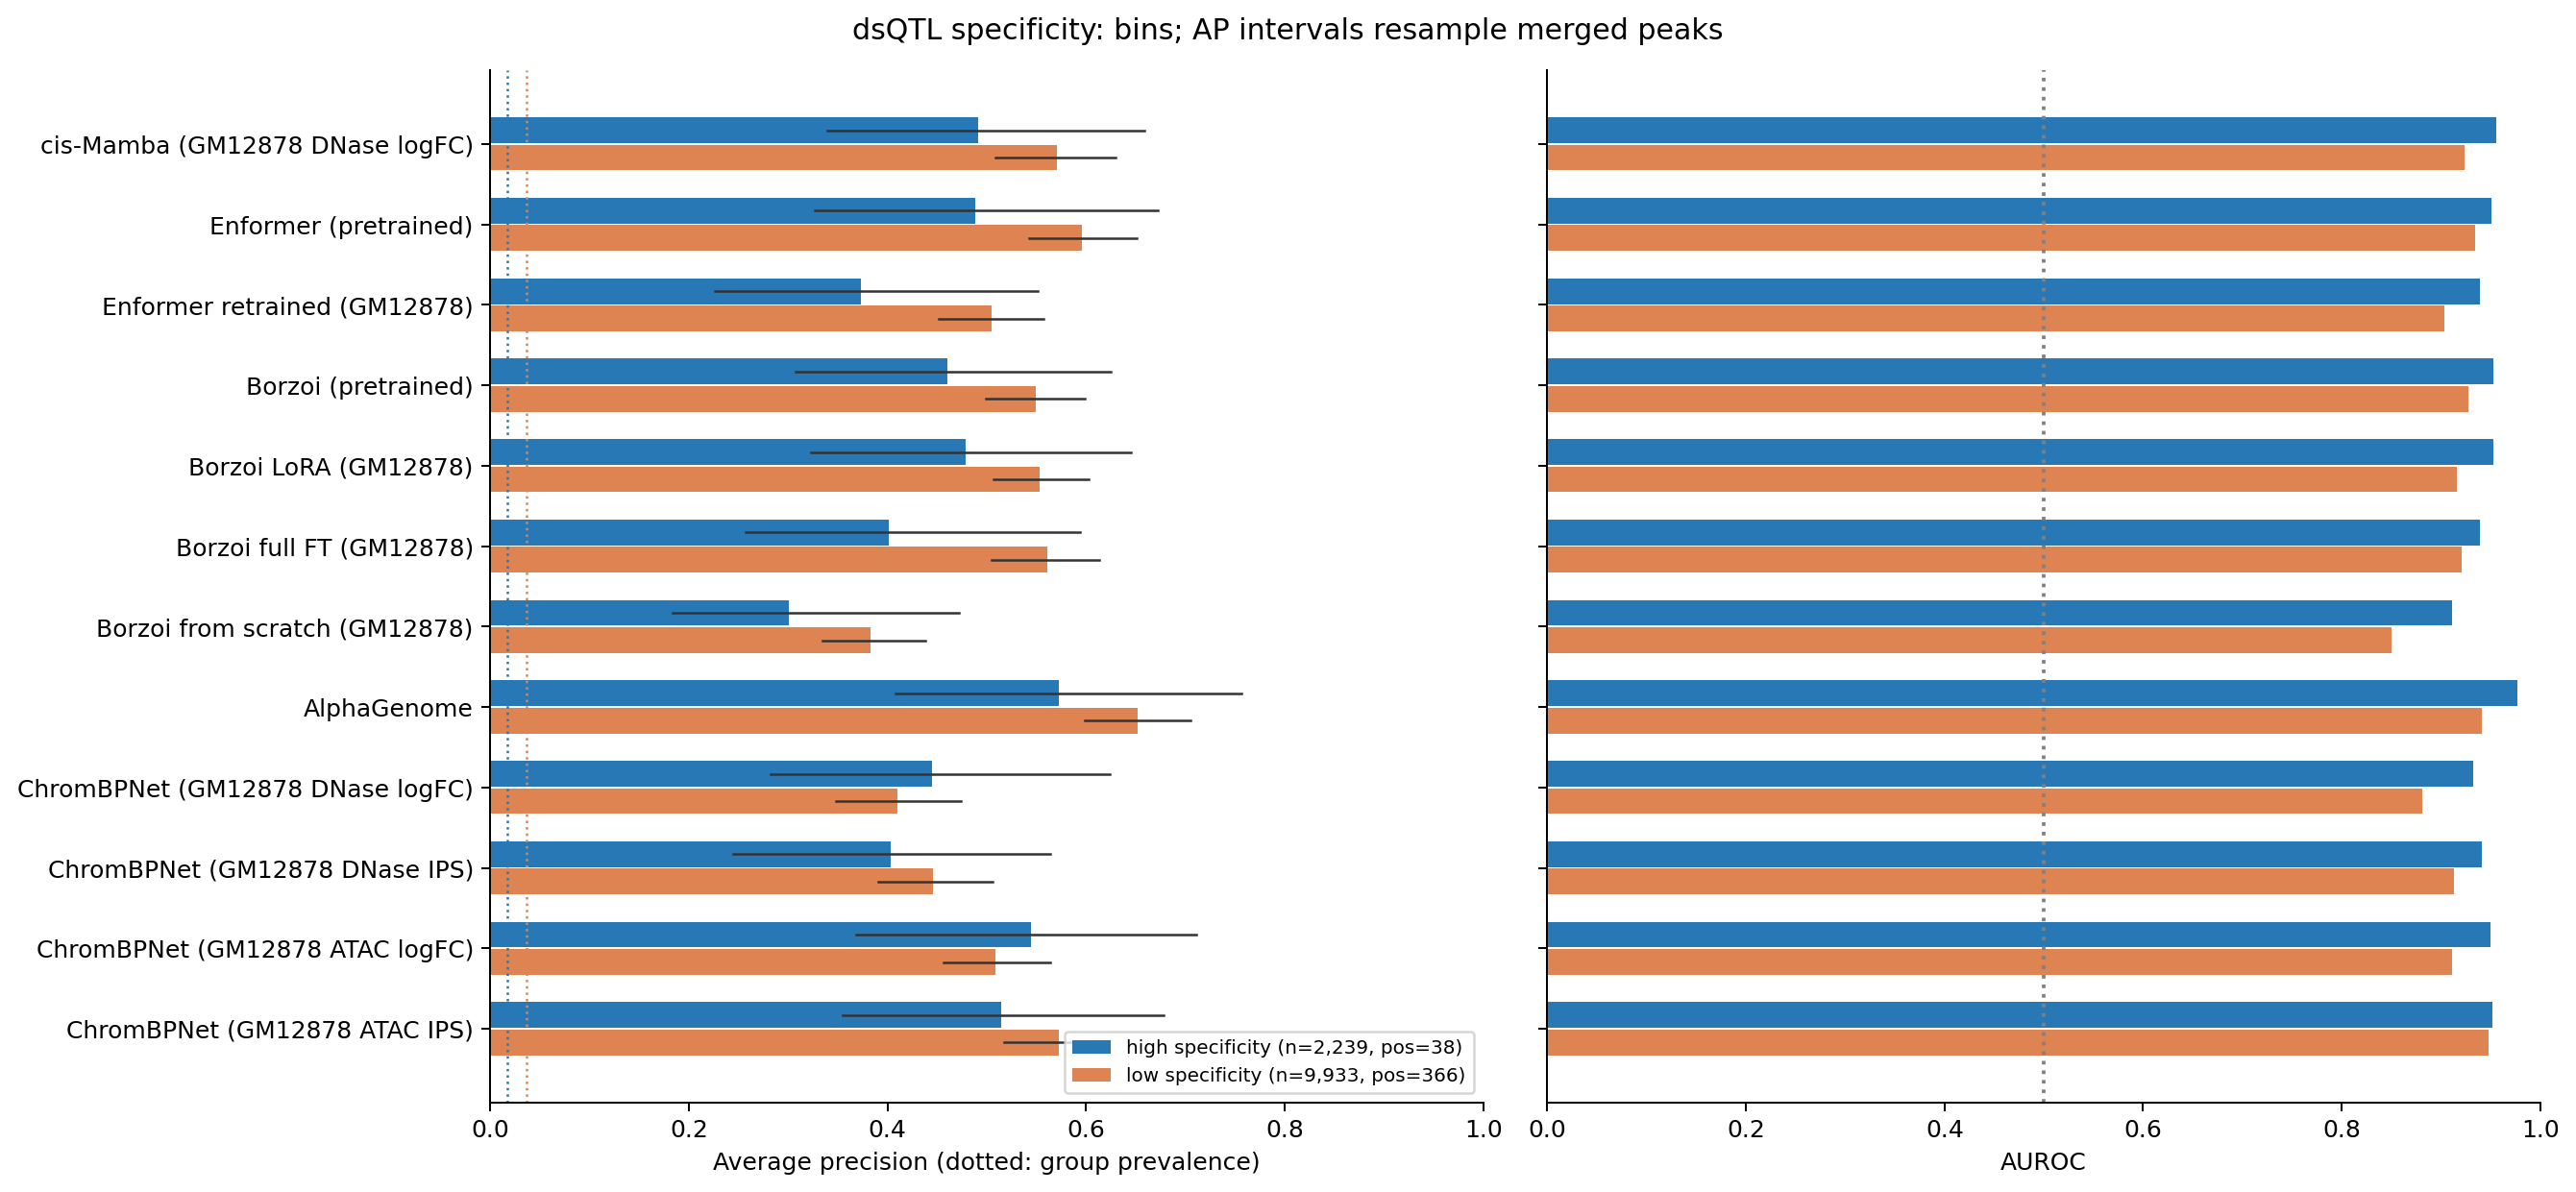

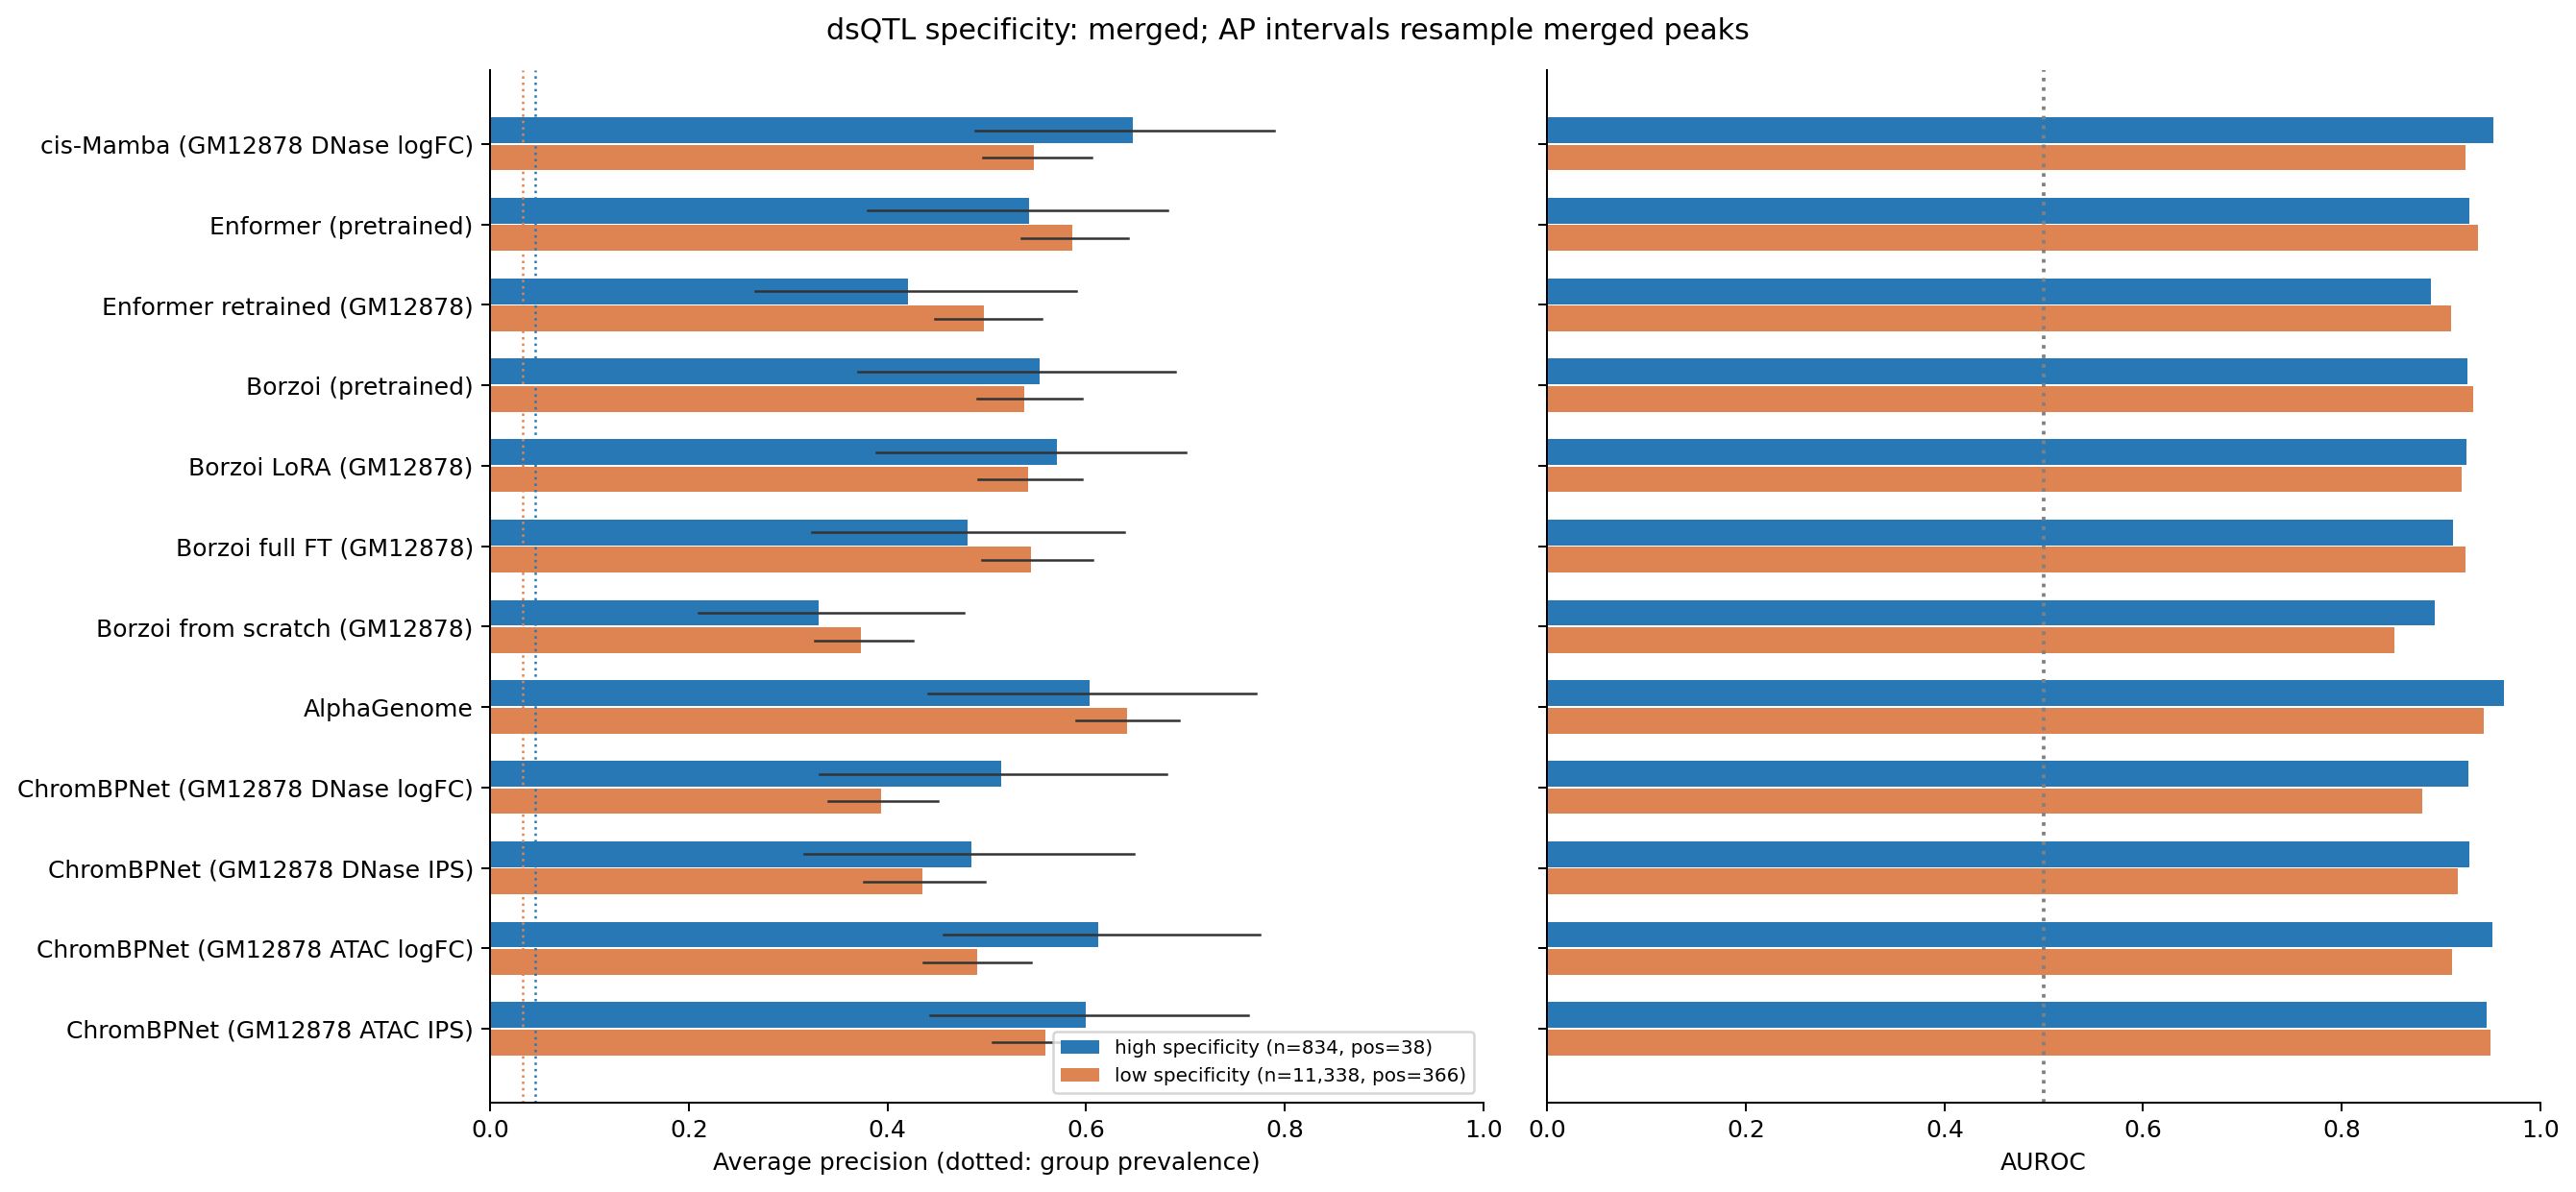

,definition,stratum,reference,model,delta_AP,ci_low,ci_high,valid_bootstraps
24,bins,high_specificity,cis-Mamba (GM12878 DNase logFC),cis-Mamba (GM12878 DNase logFC),0.0000,0.0000,0.0000,200
25,bins,high_specificity,cis-Mamba (GM12878 DNase logFC),Enformer (pretrained),0.0034,-0.1376,0.1274,200
26,bins,high_specificity,cis-Mamba (GM12878 DNase logFC),Enformer retrained (GM12878),0.1183,-0.0202,0.2551,200
27,bins,high_specificity,cis-Mamba (GM12878 DNase logFC),Borzoi (pretrained),0.0312,-0.0908,0.1715,200
28,bins,high_specificity,cis-Mamba (GM12878 DNase logFC),Borzoi LoRA (GM12878),0.0126,-0.1059,0.1455,200
29,bins,high_specificity,cis-Mamba (GM12878 DNase logFC),Borzoi full FT (GM12878),0.0907,-0.0349,0.2135,200
30,bins,high_specificity,cis-Mamba (GM12878 DNase logFC),Borzoi from scratch (GM12878),0.1907,0.0168,0.3543,200
31,bins,high_specificity,cis-Mamba (GM12878 DNase logFC),AlphaGenome,-0.0811,-0.2217,0.0767,200
32,bins,high_specificity,cis-Mamba (GM12878 DNase logFC),ChromBPNet (GM12878 DNase logFC),0.0466,-0.0991,0.2167,200
33,bins,high_specificity,cis-Mamba (GM12878 DNase logFC),ChromBPNet (GM12878 DNase IPS),0.0880,-0.0577,0.2543,200


In [7]:
from IPython.display import Image, display
for kind in ['bins','merged']:
    display(Image(filename=str(CACHE / 'figures' / f'{kind}_model_comparison.png')))
paired = pd.read_csv(CACHE / 'paired_model_differences.tsv', sep='\t')
display(paired[(paired.definition == 'bins') & paired.stratum.isin(['high_specificity','low_specificity'])].round(4))

## AUPRC presentation view

- Low specificity on the left; high specificity on the right. Fixed model colors and row order.
- Both axes start at **0.30**; numerical labels give the actual AP values.
- Random baselines and error bars omitted in this view. Original plots and uncertainty estimates remain above.
- Includes both the 128-bp-bin and merged-peak definitions; saved as PNG and PDF.

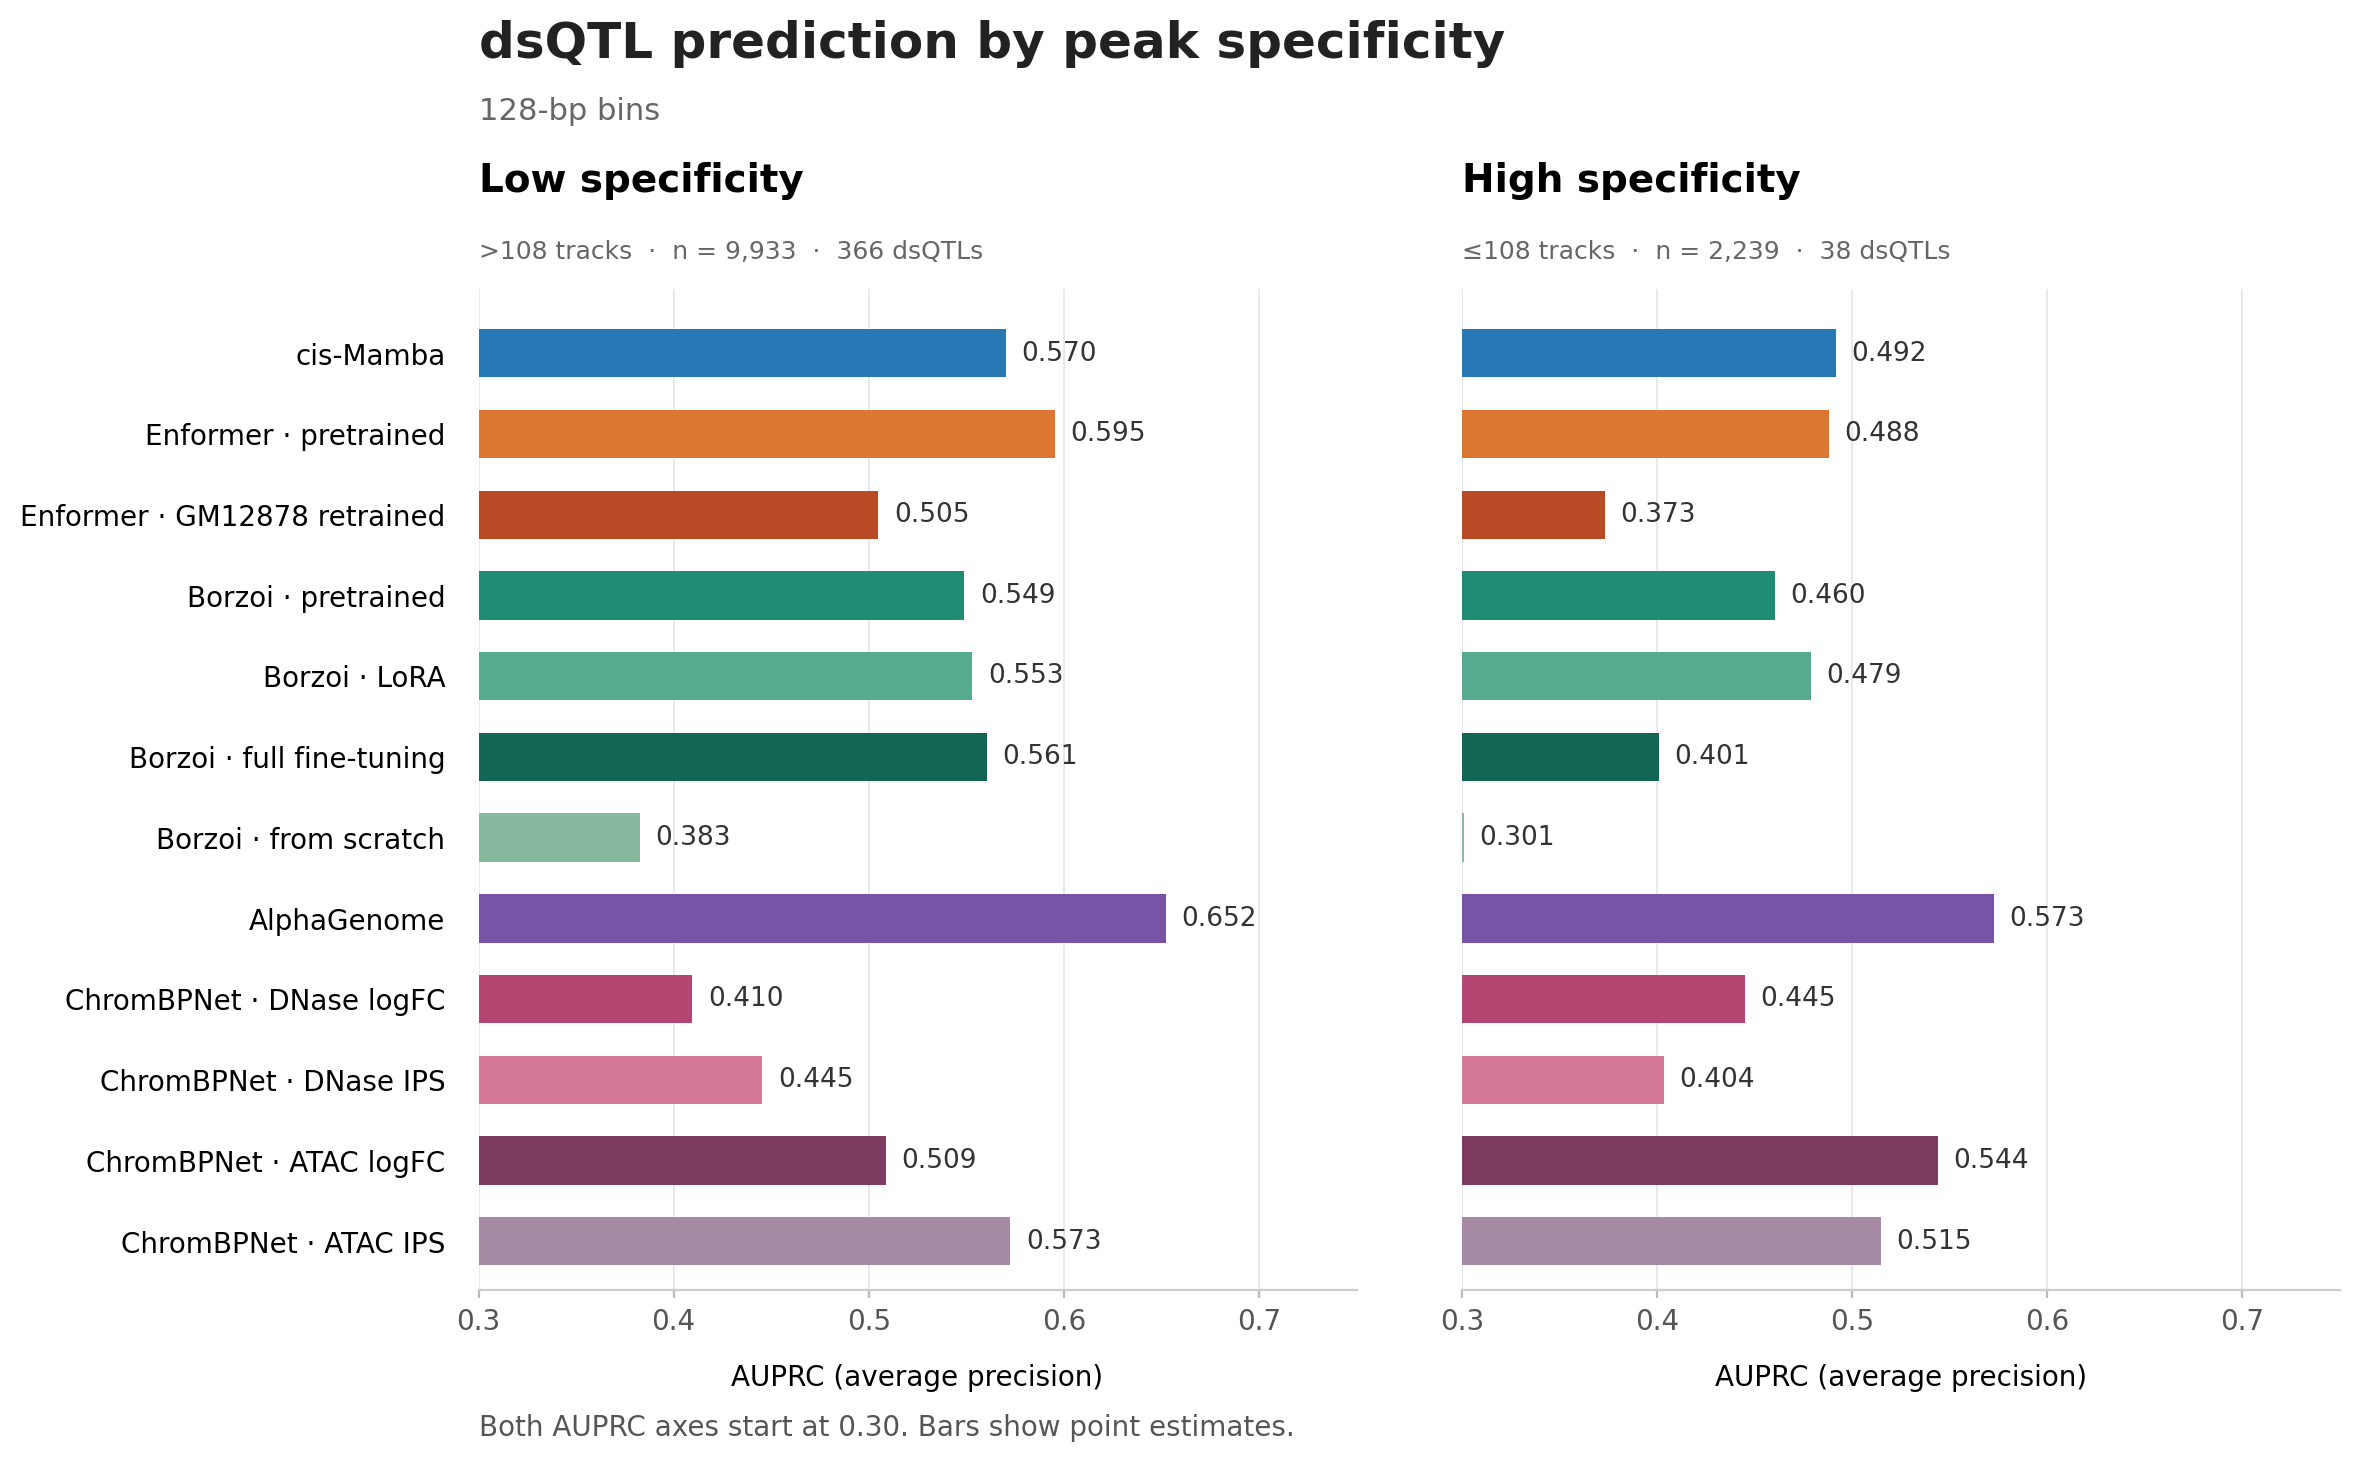

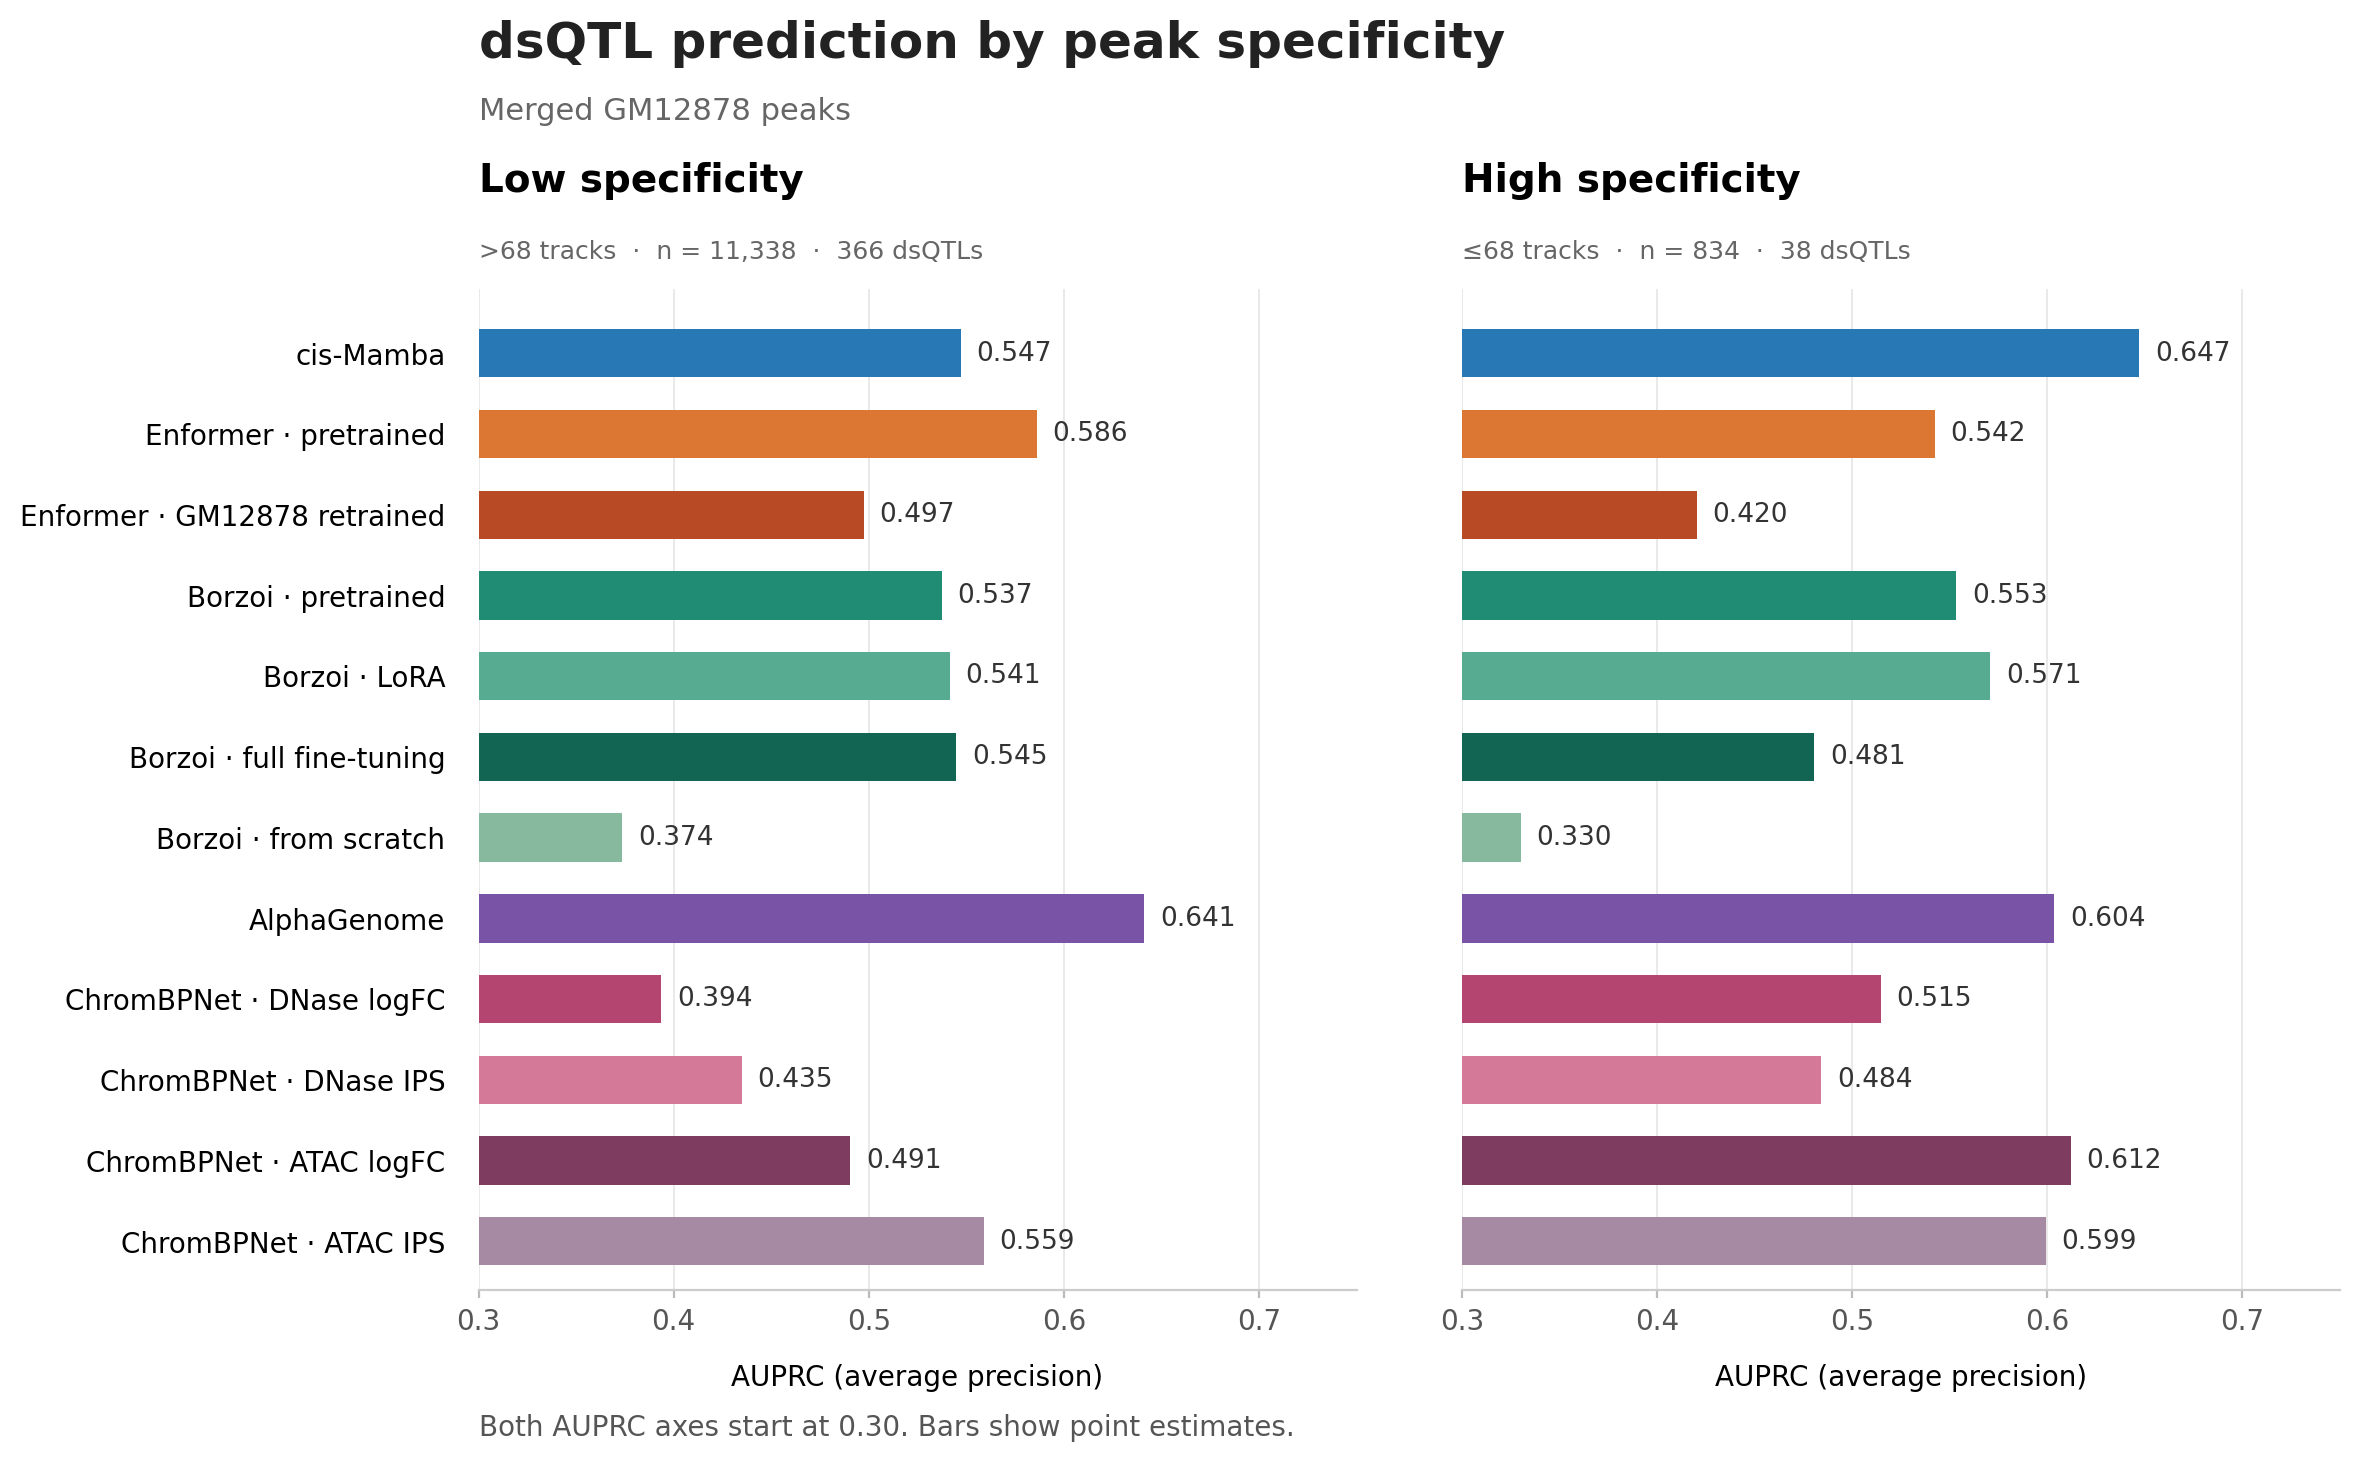

In [8]:
# Presentation view: cached AP values; fixed model order and colors across panels.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FormatStrFormatter
from IPython.display import Image, display

clean_cache = Path('/data1/lesliec/sarthak/caduceus/notebooks/benchmarks/dsqtl/dsQTL_benchmark8_cache')
clean_table = pd.read_csv(clean_cache / 'stratified_metrics.tsv', sep='\t')
clean_figdir = clean_cache / 'figures'
# Full model identifier, compact display label, fixed model color.
clean_models = [
    ('cis-Mamba (GM12878 DNase logFC)', 'cis-Mamba', '#2878B5'),
    ('Enformer (pretrained)', 'Enformer · pretrained', '#DC7633'),
    ('Enformer retrained (GM12878)', 'Enformer · GM12878 retrained', '#B84A25'),
    ('Borzoi (pretrained)', 'Borzoi · pretrained', '#218C74'),
    ('Borzoi LoRA (GM12878)', 'Borzoi · LoRA', '#56AB91'),
    ('Borzoi full FT (GM12878)', 'Borzoi · full fine-tuning', '#126553'),
    ('Borzoi from scratch (GM12878)', 'Borzoi · from scratch', '#86B99D'),
    ('AlphaGenome', 'AlphaGenome', '#7853A6'),
    ('ChromBPNet (GM12878 DNase logFC)', 'ChromBPNet · DNase logFC', '#B44470'),
    ('ChromBPNet (GM12878 DNase IPS)', 'ChromBPNet · DNase IPS', '#D57998'),
    ('ChromBPNet (GM12878 ATAC logFC)', 'ChromBPNet · ATAC logFC', '#7E3C61'),
    ('ChromBPNet (GM12878 ATAC IPS)', 'ChromBPNet · ATAC IPS', '#A68AA3'),
]
clean_xmin = 0.30
clean_subset = clean_table[clean_table.stratum.isin(['low_specificity', 'high_specificity'])]
assert clean_subset.AP.min() >= clean_xmin, 'A score falls below the displayed axis; lower clean_xmin.'
clean_xmax = np.ceil((clean_subset.AP.max() + 0.05) * 20) / 20

def plot_clean_specificity(definition):
    identifiers, labels, colors = zip(*clean_models)
    y = np.arange(len(identifiers))
    peaks = pd.read_csv(clean_cache / f'gm12878_{definition}.tsv.gz', sep='\t', usecols=['median_breadth'])
    median = int(peaks.median_breadth.iloc[0])
    with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 10,
                         'axes.spines.top': False, 'axes.spines.right': False,
                         'figure.facecolor': 'white', 'axes.facecolor': 'white'}):
        fig, axes = plt.subplots(1, 2, figsize=(13.2, 7.7), sharex=True, sharey=True)
        fig.subplots_adjust(left=0.265, right=0.97, top=0.79, bottom=0.14, wspace=0.12)
        for ax, group, title, relation in zip(
                axes, ['low_specificity', 'high_specificity'],
                ['Low specificity', 'High specificity'], ['>', '≤']):
            data = clean_table[(clean_table.definition == definition) & (clean_table.stratum == group)]
            assert not data.model.duplicated().any()
            data = data.set_index('model').loc[list(identifiers)]
            assert data.AP.notna().all()
            ax.barh(y, data.AP.to_numpy() - clean_xmin, left=clean_xmin,
                    height=0.60, color=colors, edgecolor='none', zorder=3)
            for row, value in enumerate(data.AP):
                ax.text(value + 0.008, row, f'{value:.3f}', va='center', ha='left',
                        fontsize=9.5, color='#333333')
            ax.set_xlim(clean_xmin, clean_xmax)
            ax.set_ylim(len(y) - 0.4, -0.8)
            ax.set_yticks(y, labels)
            ax.tick_params(axis='y', length=0, pad=12, labelsize=10)
            ax.tick_params(axis='x', length=3, color='#BBBBBB', labelcolor='#555555')
            ax.xaxis.set_major_locator(MultipleLocator(0.1))
            ax.xaxis.set_major_formatter(FormatStrFormatter('%.1f'))
            ax.grid(axis='x', color='#E9E9E9', linewidth=0.7, zorder=0)
            ax.set_axisbelow(True)
            ax.spines['left'].set_visible(False)
            ax.spines['bottom'].set_color('#CCCCCC')
            ax.set_title(title, loc='left', fontsize=14, weight='semibold', pad=35)
            ax.text(0, 1.025,
                    f'{relation}{median} tracks  ·  n = {int(data.n.iloc[0]):,}  ·  {int(data.positives.iloc[0])} dsQTLs',
                    transform=ax.transAxes, ha='left', va='bottom', color='#666666', fontsize=9)
            ax.set_xlabel('AUPRC (average precision)', fontsize=10, labelpad=10)
        label = '128-bp bins' if definition == 'bins' else 'Merged GM12878 peaks'
        fig.text(0.265, 0.94, 'dsQTL prediction by peak specificity', fontsize=18,
                 weight='semibold', color='#222222', ha='left')
        fig.text(0.265, 0.90, label, fontsize=11, color='#666666', ha='left')
        fig.text(0.265, 0.045, 'Both AUPRC axes start at 0.30. Bars show point estimates.',
                 ha='left', fontsize=10, color='#555555')
        stem = clean_figdir / f'{definition}_auprc_clean'
        fig.savefig(stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
        fig.savefig(stem.with_suffix('.pdf'), bbox_inches='tight')
        plt.close(fig)
        return stem.with_suffix('.png')

for clean_definition in ['bins', 'merged']:
    display(Image(filename=str(plot_clean_specificity(clean_definition))))


## Validation and reproducibility

- `test_dsqtl_benchmark8.py` checks histogram-based calls against SciPy BH across tied count distributions, bin carry across chunk boundaries, terminal-bin exclusion, bit packing, and cache reuse.
- Coverage manifest records source path, target SHA256, chromosome shapes/chunks and binning rules. Mapping and score manifests record variant hashes and input metadata; original inputs should remain immutable. Fast cached reruns do not check source paths.
- Completed chromosome markers and the final `peaks.done.json` prevent reuse of incomplete outputs. If source data or peak settings change, use a new cache directory.
- Uncertainty: normalized/clipped coverage, correlated experiments, replicate-weighted breadth, peak length, accessibility strength and differing label prevalence can affect the strata. Results describe association with breadth, not a causal effect of specificity.